In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from pandas.core.dtypes.common import is_numeric_dtype
from sklearn.neighbors import KNeighborsClassifier as knn
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [2]:
df = pd.read_csv(r"E:\Codeveda Datasets\1) iris.csv")

In [3]:
df.shape

(150, 5)

In [4]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [5]:
df.tail()

,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [7]:
df.isnull().any()

sepal_length    False
sepal_width     False
petal_length    False
petal_width     False
species         False
dtype: bool

In [8]:
df.duplicated().any()

np.True_

In [9]:
df.describe(include = "all")

,sepal_length,sepal_width,petal_length,petal_width,species
count,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,setosa
freq,NaN,NaN,NaN,NaN,50
mean,5.843333,3.054000,3.758667,1.198667,NaN
std,0.828066,0.433594,1.764420,0.763161,NaN
min,4.300000,2.000000,1.000000,0.100000,NaN
25%,5.100000,2.800000,1.600000,0.300000,NaN
50%,5.800000,3.000000,4.350000,1.300000,NaN
75%,6.400000,3.300000,5.100000,1.800000,NaN


(array([ 5.,  6., 21., 13.,  7., 21., 10., 16., 16.,  7., 15.,  2.,  5.,
         1.,  5.]),
 array([4.3 , 4.54, 4.78, 5.02, 5.26, 5.5 , 5.74, 5.98, 6.22, 6.46, 6.7 ,
        6.94, 7.18, 7.42, 7.66, 7.9 ]),
 <BarContainer object of 15 artists>)

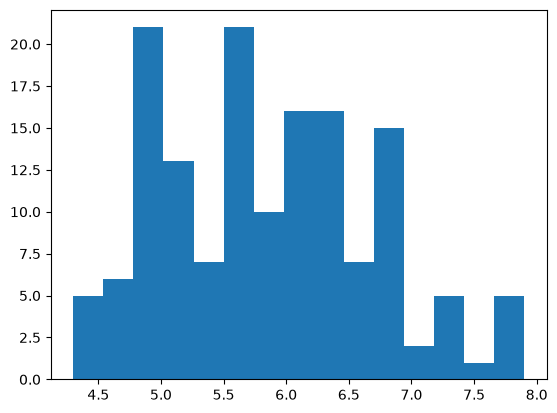

In [10]:
plt.hist(df["sepal_length"],bins = 15)

(array([ 1.,  7.,  3., 13., 23., 10., 38., 13., 18.,  9.,  3.,  8.,  1.,
         2.,  1.]),
 array([2.  , 2.16, 2.32, 2.48, 2.64, 2.8 , 2.96, 3.12, 3.28, 3.44, 3.6 ,
        3.76, 3.92, 4.08, 4.24, 4.4 ]),
 <BarContainer object of 15 artists>)

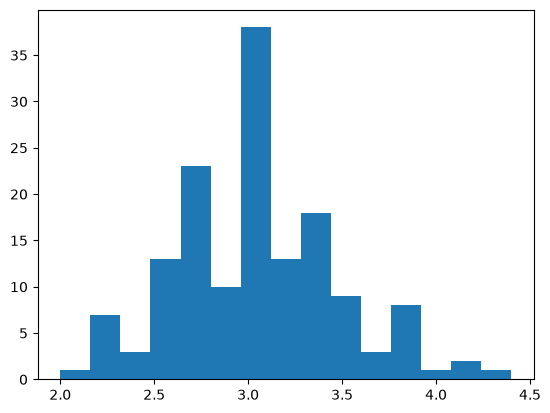

In [11]:
plt.hist(df["sepal_width"],bins = 15)

(array([11., 37.,  2.,  0.,  0.,  3.,  4., 12., 18., 17., 16., 14., 10.,
         2.,  4.]),
 array([1.        , 1.39333333, 1.78666667, 2.18      , 2.57333333,
        2.96666667, 3.36      , 3.75333333, 4.14666667, 4.54      ,
        4.93333333, 5.32666667, 5.72      , 6.11333333, 6.50666667,
        6.9       ]),
 <BarContainer object of 15 artists>)

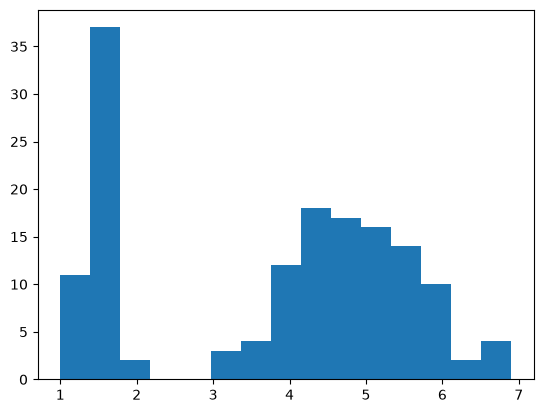

In [12]:
plt.hist(df["petal_length"],bins = 15)

(array([34., 14.,  1.,  1.,  0.,  7.,  8., 13., 20.,  6., 12., 11.,  6.,
        11.,  6.]),
 array([0.1 , 0.26, 0.42, 0.58, 0.74, 0.9 , 1.06, 1.22, 1.38, 1.54, 1.7 ,
        1.86, 2.02, 2.18, 2.34, 2.5 ]),
 <BarContainer object of 15 artists>)

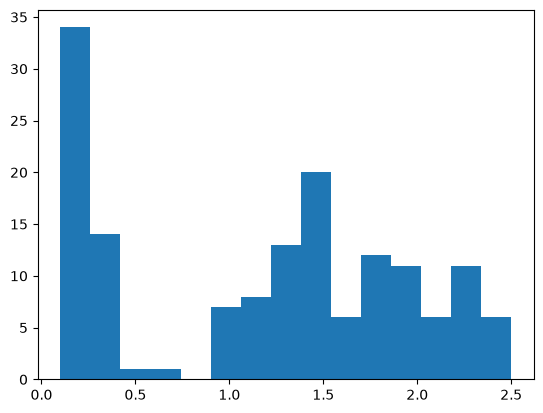

In [13]:
plt.hist(df["petal_width"],bins = 15)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12096\891408485.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["sepal_length"])


<Axes: xlabel='sepal_length', ylabel='Density'>

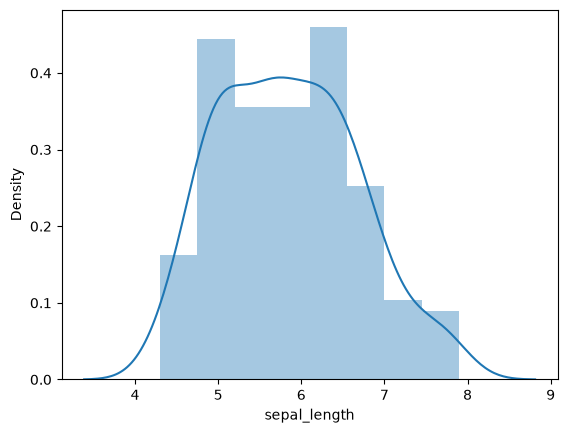

In [14]:
sns.distplot(df["sepal_length"])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12096\664177273.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["sepal_width"])


<Axes: xlabel='sepal_width', ylabel='Density'>

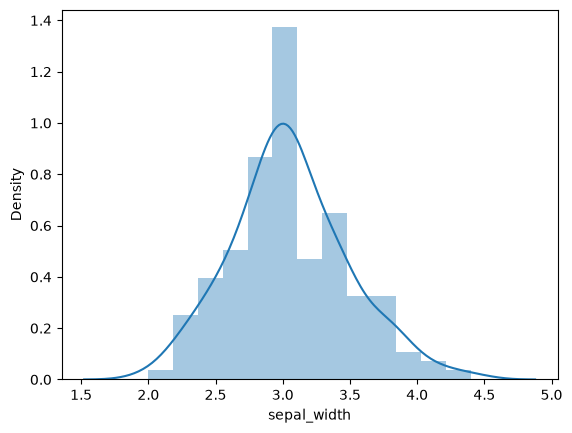

In [15]:
sns.distplot(df["sepal_width"])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12096\2807225282.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["petal_length"])


<Axes: xlabel='petal_length', ylabel='Density'>

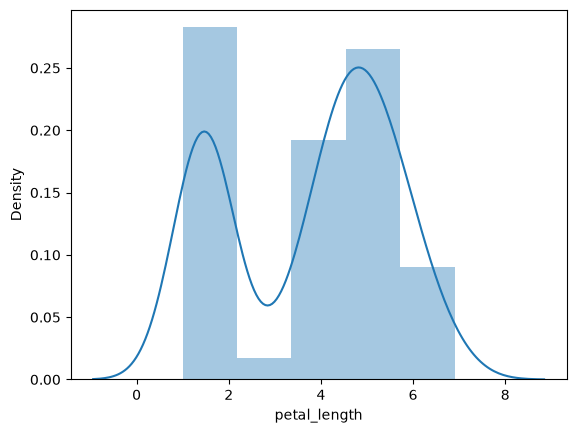

In [16]:
sns.distplot(df["petal_length"])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12096\3919348056.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["petal_width"])


<Axes: xlabel='petal_width', ylabel='Density'>

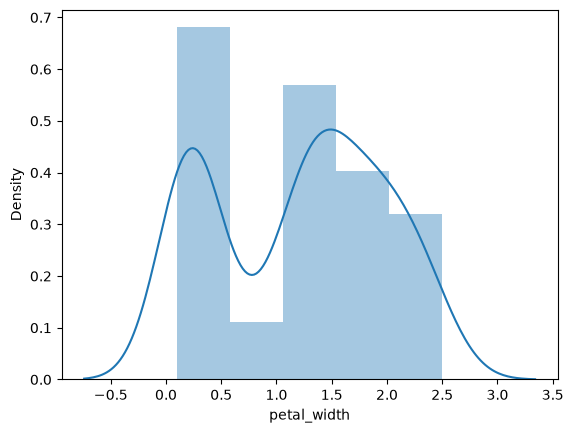

In [17]:
sns.distplot(df["petal_width"])

<Axes: ylabel='sepal_length'>

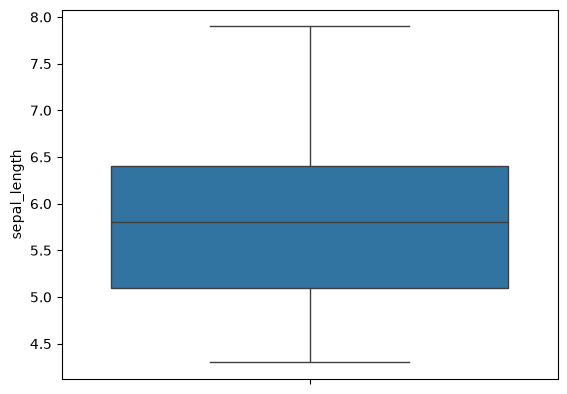

In [18]:
sns.boxplot(df["sepal_length"])

<Axes: ylabel='sepal_width'>

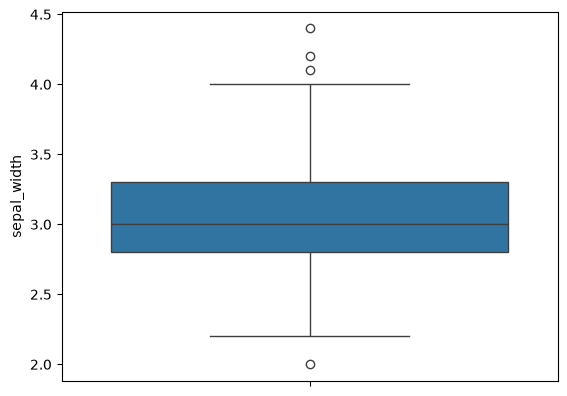

In [19]:
sns.boxplot(df["sepal_width"])

<Axes: ylabel='petal_length'>

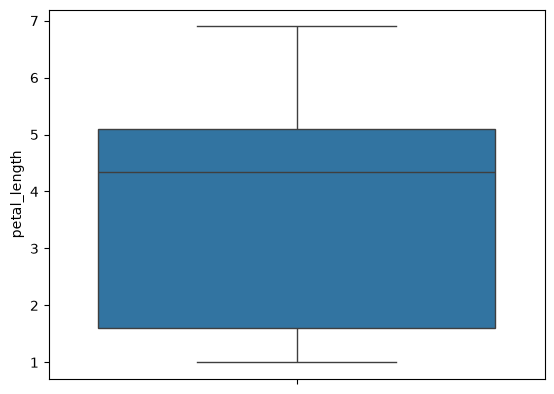

In [20]:
sns.boxplot(df["petal_length"])

<Axes: ylabel='petal_width'>

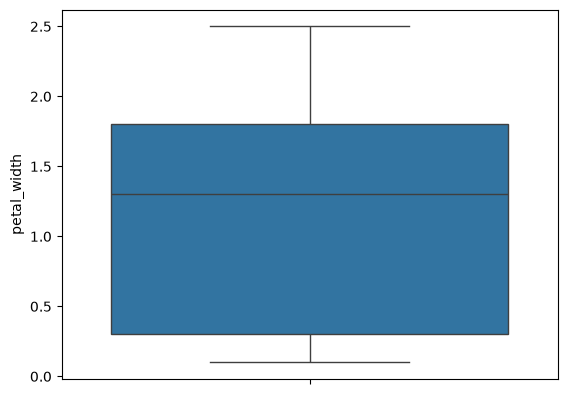

In [21]:
sns.boxplot(df["petal_width"])

<Axes: xlabel='count', ylabel='species'>

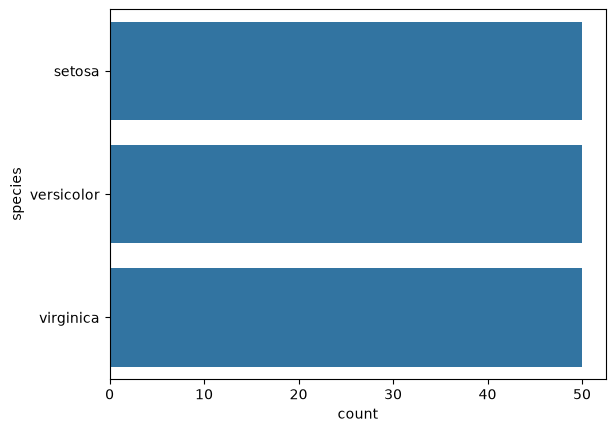

In [22]:
sns.countplot(df["species"])

<Axes: >

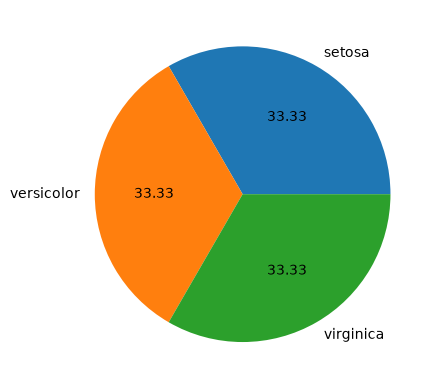

In [23]:
df["species"].value_counts().plot(kind='pie',autopct='%.2f')

<Axes: xlabel='sepal_length', ylabel='sepal_width'>

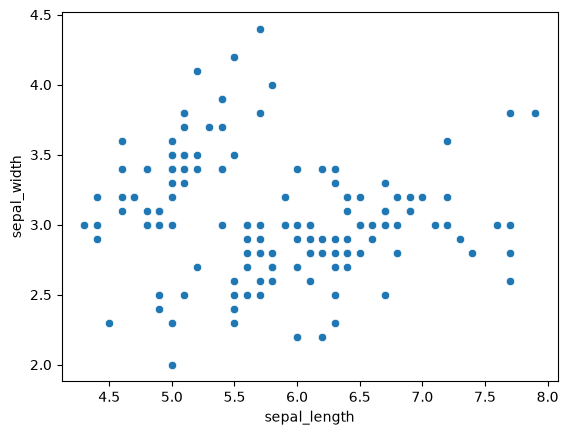

In [24]:
sns.scatterplot(x=df["sepal_length"],y=df["sepal_width"])

<Axes: xlabel='petal_length', ylabel='petal_width'>

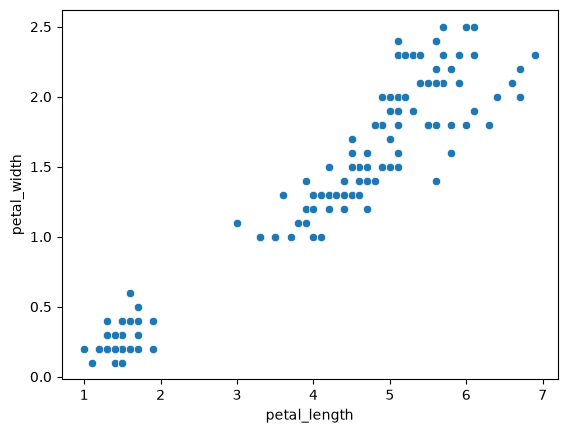

In [25]:
sns.scatterplot(x=df["petal_length"],y=df["petal_width"])

<Axes: xlabel='sepal_length', ylabel='sepal_width'>

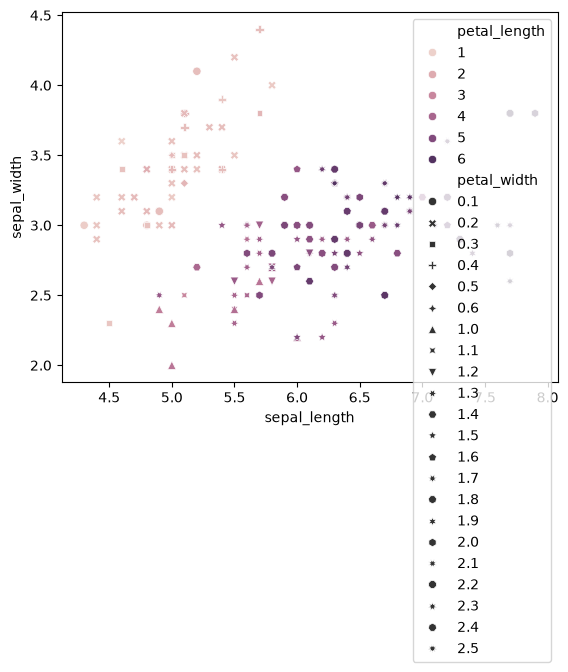

In [26]:
sns.scatterplot(x=df["sepal_length"],y=df["sepal_width"],hue=df["petal_length"],style=df["petal_width"])

<Axes: xlabel='species', ylabel='sepal_length'>

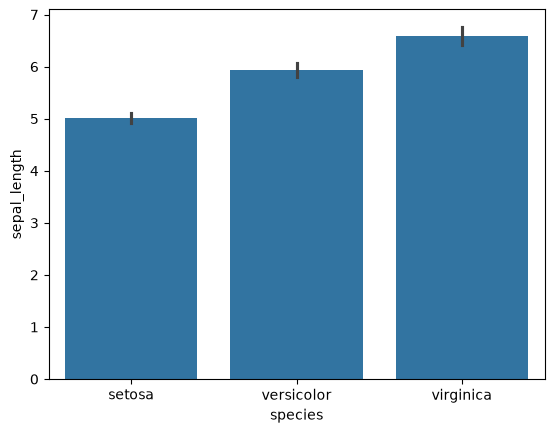

In [27]:
sns.barplot(x=df["species"],y=df["sepal_length"])

<Axes: xlabel='species', ylabel='sepal_width'>

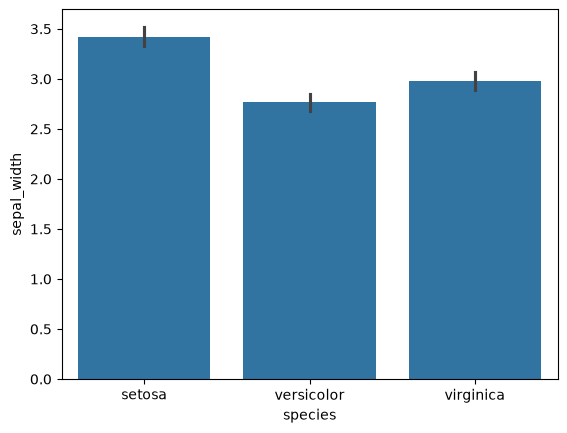

In [28]:
sns.barplot(x=df["species"],y=df["sepal_width"])

<Axes: xlabel='species', ylabel='petal_length'>

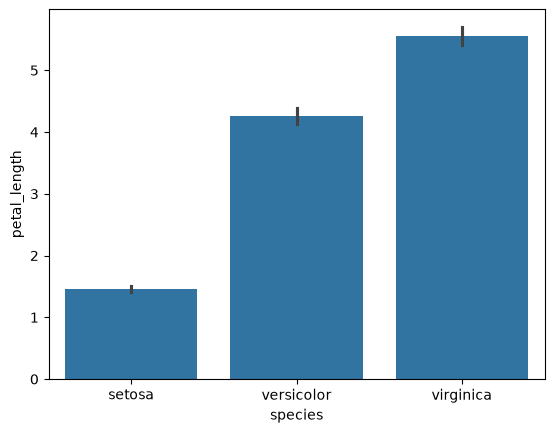

In [29]:
sns.barplot(x=df["species"],y=df["petal_length"])

<Axes: xlabel='species', ylabel='petal_width'>

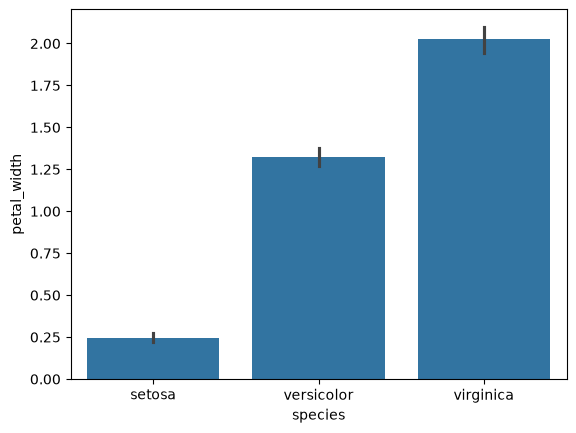

In [30]:
sns.barplot(x=df["species"],y=df["petal_width"])

In [31]:
label = LabelEncoder()

In [32]:
for column in df.columns:
    if is_numeric_dtype(df[column]):
        continue
    else:
        df[column] = label.fit_transform(df[column])

In [33]:
df.corr()

,sepal_length,sepal_width,petal_length,petal_width,species
sepal_length,1.000000,-0.109369,0.871754,0.817954,0.782561
sepal_width,-0.109369,1.000000,-0.420516,-0.356544,-0.419446
petal_length,0.871754,-0.420516,1.000000,0.962757,0.949043
petal_width,0.817954,-0.356544,0.962757,1.000000,0.956464
species,0.782561,-0.419446,0.949043,0.956464,1.000000


<Axes: >

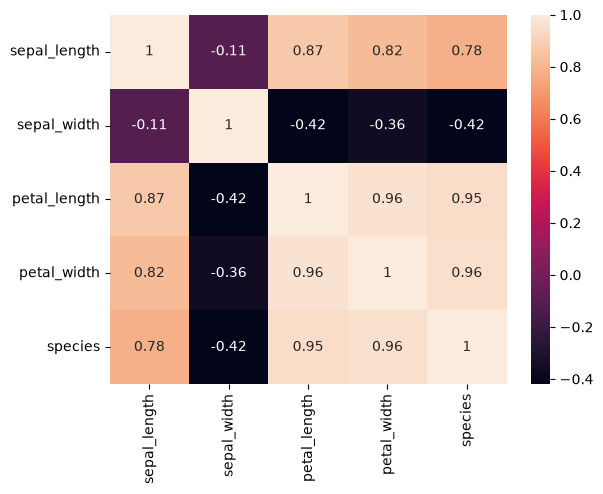

In [34]:
sns.heatmap(df.corr(),annot=True)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12096\107776459.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df)


<Axes: ylabel='Density'>

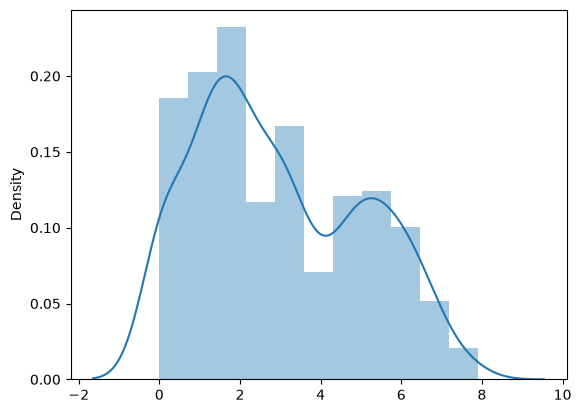

In [35]:
sns.distplot(df)

In [36]:
x=df.drop("species",axis=1)
y=df["species"]

In [37]:
min_max = MinMaxScaler()
X= min_max.fit_transform(x)
X= pd.DataFrame(X, columns = x.columns)

In [38]:
X.head()

,sepal_length,sepal_width,petal_length,petal_width
0,0.222222,0.625000,0.067797,0.041667
1,0.166667,0.416667,0.067797,0.041667
2,0.111111,0.500000,0.050847,0.041667
3,0.083333,0.458333,0.084746,0.041667
4,0.194444,0.666667,0.067797,0.041667


In [39]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: species, dtype: int64

In [40]:
xtrain,xtest,ytrain,ytest =  train_test_split(X,y, train_size=0.70,random_state=23)

In [41]:
k_value = [1,3,5,7,9,11,13,15,17,19,21,23,25,27,29]
result = []

In [42]:
for k in k_value:
    model = knn(n_neighbors=k)
    model.fit(xtrain,ytrain)
    ypred = model.predict(xtest)
    accuracy = accuracy_score(ytest,ypred)
    result.append({"K:",k,"Accuracy:",accuracy})

In [43]:
print(f"\nK = {k}")
print("Accuracy:",round(accuracy,4))
print("\nClassification Report")
print(classification_report(ytest,ypred,target_names = ["setosa","versicolor","virginica"],zero_division=0 ))


K = 29
Accuracy: 0.9778

Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        18
  versicolor       0.93      1.00      0.97        14
   virginica       1.00      0.92      0.96        13

    accuracy                           0.98        45
   macro avg       0.98      0.97      0.98        45
weighted avg       0.98      0.98      0.98        45



In [49]:
cm = confusion_matrix(ytest, ypred)

sns.heatmap(cm,
           annot=True,
           cmap="Blues" 
           xticklabels=["setosa","versicolor","virginica"],
           yticklabels=["setosa","versicolor","virginica"])
plt.xlabel("predicted label")
plt.ylabel("actual label")
plt.title("KNN Confuction Matrix")
plt.show()

SyntaxError: invalid syntax. Perhaps you forgot a comma? (2753947594.py, line 5)